# Comparación de dos medias

En Estadística Inferencial I aprendieron a comparar dos medias poblacionales mediante pruebas de hipótesis. Sin embargo, **antes de realizar los cálculos es necesario identificar qué prueba corresponde al problema**. La selección depende de cómo se obtuvieron los datos y de las características de sus distribuciones.

En esta guía retomaremos la forma de trabajo que hemos utilizado durante el curso: organizar las observaciones en archivos **CSV**, leerlos con `pandas` y manipular sus columnas mediante un *DataFrame* (`df`). A partir de la misma base de datos, aprenderemos a elegir e interpretar distintas pruebas de comparación de medias.

Para tomar esa decisión consideraremos principalmente:

- Si las muestras son **independientes o pareadas**.
- Si es razonable suponer **normalidad**.
- Si las varianzas poblacionales pueden considerarse **iguales o diferentes**.

El siguiente diagrama resume las rutas que estudiaremos.

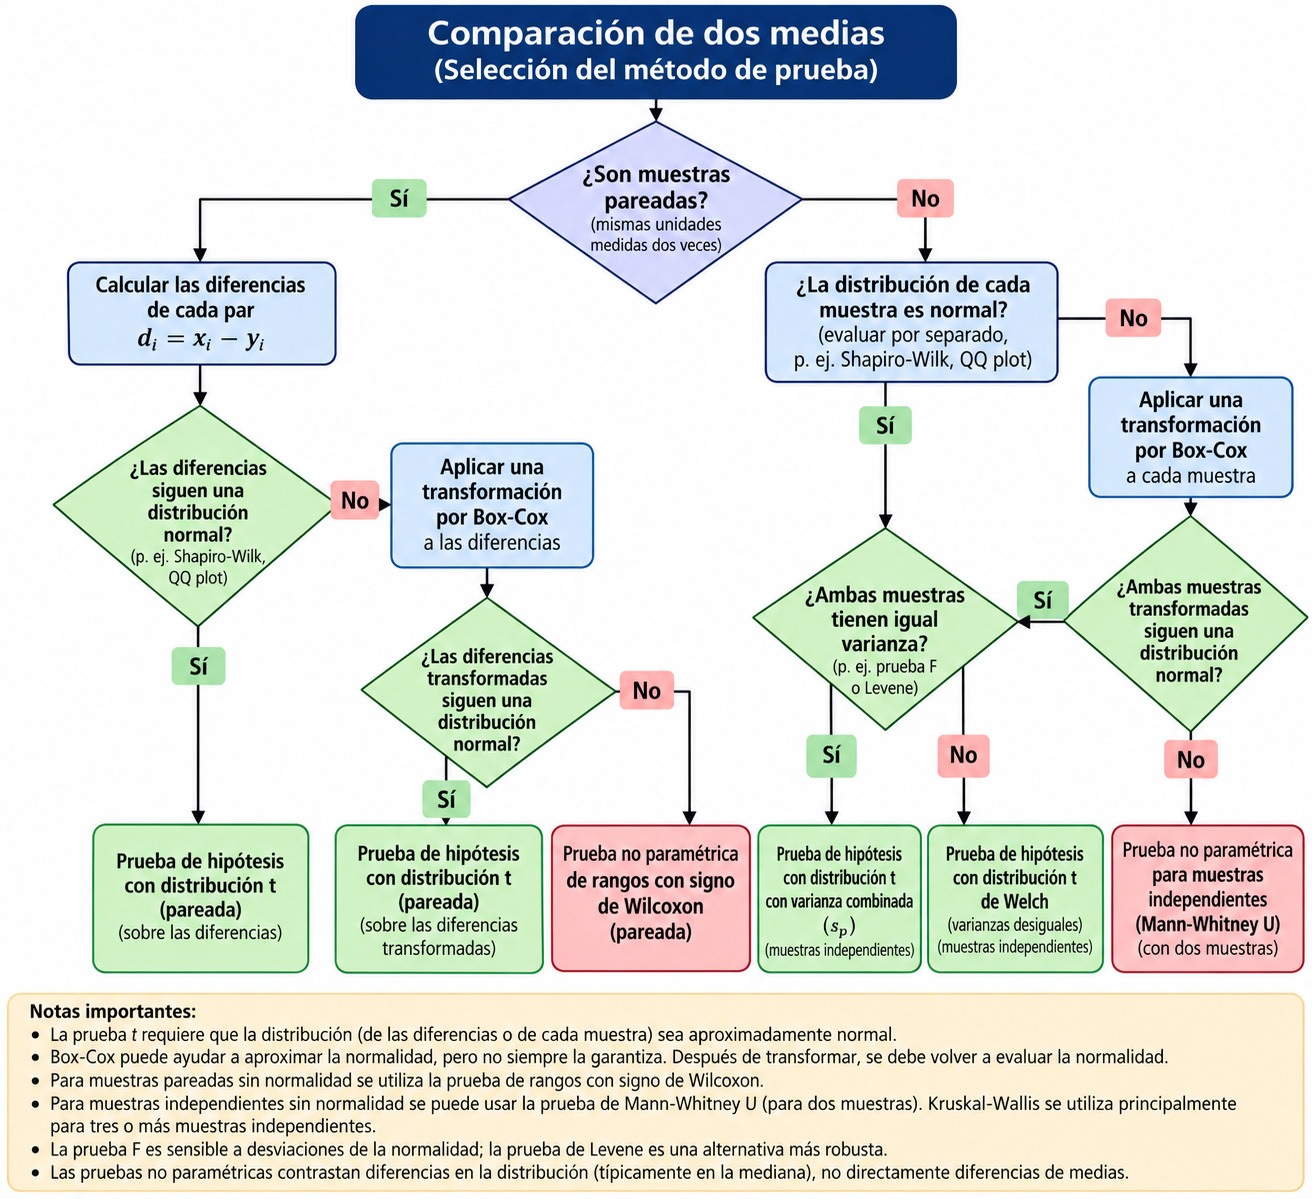

El diagrama es una **herramienta de orientación**, no una regla automática basada exclusivamente en valores-p. También debemos considerar el diseño del estudio, el tamaño de las muestras, los valores atípicos y el objetivo de la investigación.

Primero seguiremos la ruta correspondiente a **muestras independientes** y, posteriormente, abordaremos el caso de **muestras pareadas**. Esta revisión nos servirá como base para introducir el análisis de varianza (ANOVA) y los diseños experimentales.


## Muestras independientes y pareadas

La primera pregunta del diagrama es: **¿las muestras son pareadas?**

Dos muestras son **independientes** cuando las observaciones de un grupo no tienen una correspondencia individual con las del otro. Por ejemplo, si 15 estudiantes utilizan el Método 1 y otros 15 utilizan el Método 2, las calificaciones pertenecen a estudiantes diferentes.

En cambio, las muestras son **pareadas** cuando las observaciones se vinculan por una razón experimental: los mismos estudiantes se evalúan antes y después de una intervención, o dos personas se emparejan según características previamente definidas.

Esta distinción importa porque, en las muestras independientes, se comparan las medias de dos grupos; en las pareadas, se analiza la **diferencia dentro de cada pareja**.

**Importante:** que dos columnas tengan el mismo número de filas no significa que las muestras estén pareadas. El vínculo debe existir desde el diseño de la investigación. Cuando se trabaja con archivos CSV, ese vínculo debe poder identificarse, por ejemplo, mediante una columna de identificación del participante.


## Ejemplo: comparación de dos métodos de estudio

Un investigador desea comparar las calificaciones obtenidas por estudiantes que utilizan dos estrategias de preparación para un examen:

- **Método 1 (M1):** estudio tradicional mediante apuntes y lectura teórica.
- **Método 2 (M2):** estudio apoyado en guías de ejercicios resueltos.

Participaron **30 estudiantes**, de los cuales 15 utilizaron M1 y 15 utilizaron M2. Cada participante empleó un solo método; por tanto, se analizarán como **muestras independientes**.

Nuestro objetivo es determinar si las medias poblacionales de calificación difieren entre ambos métodos.

### Organización de los datos en CSV

En unidades anteriores hemos organizado las bases de datos de forma que **cada fila representa una observación y cada columna una variable**. Conservaremos exactamente ese formato.

La base contiene dos columnas:

- `metodo`: variable categórica que identifica el método aplicado (`M1` o `M2`).
- `calificacion`: variable numérica de respuesta.

En el siguiente bloque, el contenido CSV se escribe dentro de la variable `datos`. Se utiliza `StringIO` para que `pd.read_csv()` pueda leer ese texto como si fuera un archivo. Cuando se disponga de un archivo CSV guardado, se podrá leer de la manera habitual con `pd.read_csv("nombre_del_archivo.csv")`.

El resultado es el *DataFrame* `df`, que utilizaremos en los análisis posteriores.


In [ ]:
import pandas as pd
from io import StringIO

datos = '''
metodo,calificacion
M1,64
M1,66
M1,65
M1,67
M1,68
M1,68
M1,70
M1,69
M1,71
M1,72
M1,72
M1,74
M1,73
M1,75
M1,76
M2,71
M2,72
M2,73
M2,74
M2,73
M2,75
M2,76
M2,74
M2,78
M2,77
M2,79
M2,81
M2,80
M2,82
M2,83
'''

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df

,metodo,calificacion
0,M1,64
1,M1,66
2,M1,65
3,M1,67
4,M1,68
5,M1,68
6,M1,70
7,M1,69
8,M1,71
9,M1,72


### Cómo se trabaja con el DataFrame

Observa que las calificaciones de ambos métodos se encuentran en **una sola columna**. No necesitamos crear manualmente dos columnas de datos. La variable `metodo` indica a qué grupo pertenece cada observación y `calificacion` guarda la respuesta numérica.

La instrucción `pd.read_csv(StringIO(datos))` construye la tabla a partir del texto con formato CSV. Por su parte, `reset_index(drop=True)` restablece los índices de las filas. Esta operación no altera las calificaciones.

A continuación separaremos temporalmente las observaciones de M1 y M2 mediante filtros sobre `df`. Estas nuevas variables servirán para realizar las pruebas estadísticas, pero **la base de datos original conserva su estructura**.


In [ ]:
# Calificaciones del Método 1
metodo_1 = df[df["metodo"] == "M1"]["calificacion"]

# Calificaciones del Método 2
metodo_2 = df[df["metodo"] == "M2"]["calificacion"]

print("Media M1:", metodo_1.mean())
print("Media M2:", metodo_2.mean())
print("Desviación estándar M1", metodo_1.std())
print("Desviación estándar M2", metodo_2.std())
print("Varianza M1:", metodo_1.var())
print("Varianza M2:", metodo_2.var())

Media M1: 70.0
Media M2: 76.53333333333333
Desviación estándar M1 3.6839419880650364
Desviación estándar M2 3.8147583085145715
Varianza M1: 13.571428571428571
Varianza M2: 14.552380952380954


### Estadística descriptiva inicial

Las expresiones `df[df["metodo"] == "M1"]["calificacion"]` y `df[df["metodo"] == "M2"]["calificacion"]` seleccionan las calificaciones correspondientes a cada método. Así obtenemos las series `metodo_1` y `metodo_2` sin modificar `df`.

Con `.mean()`, `.std()` y `.var()` calculamos la media, desviación estándar y varianza **muestrales**. En `pandas`, las funciones `.std()` y `.var()` utilizan por defecto el divisor $n-1$.

Los resultados descriptivos de esta base son:

| Estadístico | M1 | M2 |
|---|---:|---:|
| Número de estudiantes | 15 | 15 |
| Media | 70.0000 | 76.5333 |
| Desviación estándar | 3.6839 | 3.8148 |
| Varianza | 13.5714 | 14.5524 |

La diferencia de medias muestrales es de aproximadamente **6.5333 puntos a favor de M2**. Sin embargo, una diferencia observada en la muestra no basta para afirmar que exista una diferencia poblacional; para ello realizaremos una prueba de hipótesis.


### Evaluación de normalidad

Como estamos comparando dos muestras independientes, evaluaremos **cada grupo por separado**. La prueba t clásica se basa en la normalidad de las poblaciones de origen, aunque puede tolerar desviaciones moderadas de ese supuesto.

Utilizaremos tres herramientas conocidas:

- **Shapiro-Wilk:** aporta un contraste estadístico de normalidad.
- **Gráfico Q-Q:** permite observar desviaciones respecto a una distribución normal.
- **Histograma:** permite revisar visualmente la forma y dispersión de los datos, así como posibles valores atípicos.

Las hipótesis de Shapiro-Wilk son:

$$
H_0:\ \text{La distribución de los datos es normal}
$$

$$
H_1:\ \text{La distribución de los datos no es normal}
$$

En los siguientes **dos bloques de código** se repite el mismo procedimiento: primero para `metodo_1` y después para `metodo_2`. En ambos casos se imprime el valor-p de Shapiro-Wilk y se presentan un gráfico Q-Q y un histograma.

Si el valor-p es menor que el nivel de significancia, existe evidencia para rechazar la normalidad. Si es mayor, **no se rechaza $H_0$**, pero esto no demuestra que los datos sean perfectamente normales. Es recomendable interpretar el valor-p junto con los gráficos, especialmente cuando las muestras son pequeñas.


valor-p (Shapiro) = 0.8856781355272578


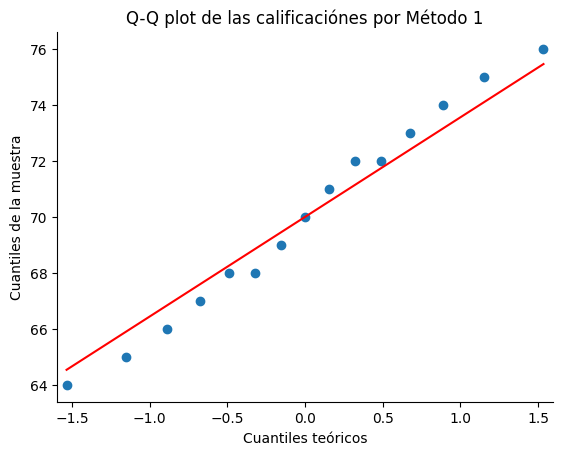

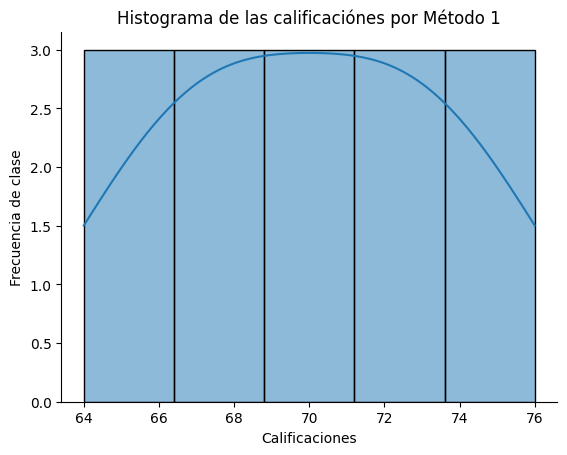

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Prueba de Shapiro-Wilk
# H0: Los datos proceden de una distribución normal
# H1: Los datos no proceden de una distribución normal
stat, valor_p_sh = shapiro(metodo_1)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(metodo_1, line='s')
plt.title("Q-Q plot de las calificaciónes por Método 1")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de la muestra")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Histograma
sns.histplot(metodo_1, kde=True)
plt.title("Histograma de las calificaciónes por Método 1")
plt.xlabel("Calificaciones")
plt.ylabel("Frecuencia de clase")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

valor-p (Shapiro) = 0.5257214760823039


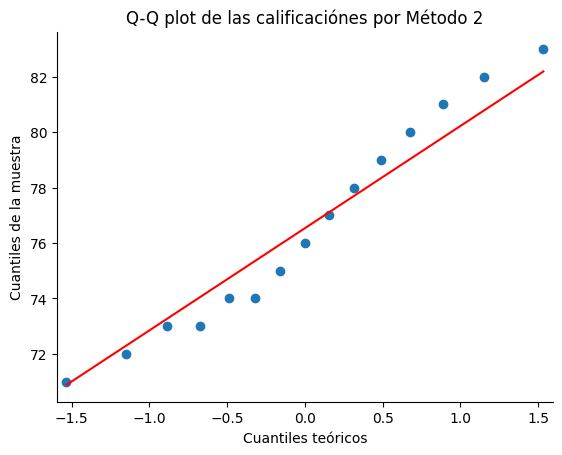

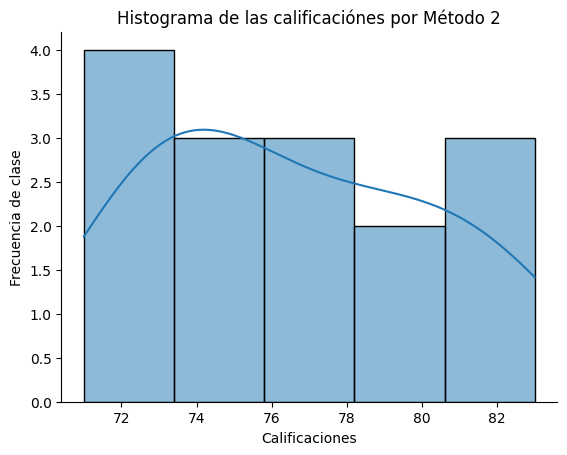

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Prueba de Shapiro-Wilk
# H0: Los datos proceden de una distribución normal
# H1: Los datos no proceden de una distribución normal
stat, valor_p_sh = shapiro(metodo_2)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(metodo_2, line='s')
plt.title("Q-Q plot de las calificaciónes por Método 2")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de la muestra")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Histograma
sns.histplot(metodo_2, kde=True)
plt.title("Histograma de las calificaciónes por Método 2")
plt.xlabel("Calificaciones")
plt.ylabel("Frecuencia de clase")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

### Interpretación de la normalidad

Con estos datos, los valores-p aproximados de Shapiro-Wilk son:

| Método | Valor-p |
|---|---:|
| M1 | 0.8857 |
| M2 | 0.5257 |

Para $\alpha=0.05$, no se rechaza la hipótesis de normalidad en ninguna de las dos muestras. Esto es **compatible** con el uso de una prueba paramétrica, siempre que no se observen desviaciones preocupantes en los gráficos y el resto de las condiciones del estudio también sean razonables.

**Nota:** la independencia de las observaciones no se comprueba mediante Shapiro-Wilk; se fundamenta en la forma en que se seleccionaron y asignaron los estudiantes.


### Evaluación de homocedasticidad

El siguiente paso es revisar la **homogeneidad de varianzas**, también llamada *homocedasticidad*. Nos interesa saber si la variabilidad poblacional de las calificaciones es comparable entre M1 y M2, aun cuando las medias puedan ser diferentes.

Las hipótesis son:

$$
H_0: \sigma_1^2 = \sigma_2^2
$$

$$
H_1: \sigma_1^2 \neq \sigma_2^2
$$

El siguiente bloque calcula tres contrastes:

1. **Prueba F bilateral:** compara directamente las varianzas muestrales. Es sensible a la falta de normalidad.
2. **Levene centrado en la media:** compara la dispersión de los dos grupos respecto a sus medias.
3. **Levene centrado en la mediana (Brown-Forsythe):** utiliza la mediana como referencia y suele ser más robusto frente a asimetría y valores atípicos.

En el código, `F1` y `F2` son cocientes recíprocos de las varianzas, mientras que `Fs.sort()` los ordena. Como **las dos muestras tienen el mismo tamaño**, sus grados de libertad coinciden y la suma de las probabilidades de las colas correspondientes produce el valor-p bilateral utilizado aquí. Para tamaños muestrales diferentes sería necesario ajustar el cálculo respetando los grados de libertad del cociente elegido.


In [ ]:

from scipy.stats import f, levene

# Prueba F bilateral
F1 = metodo_1.var() / metodo_2.var()
F2 = metodo_2.var() / metodo_1.var()
Fs = [F1, F2]
Fs.sort()

gl1 = len(metodo_1) - 1
gl2 = len(metodo_2) - 1

valor_p_F = f.cdf(Fs[0], gl1, gl2) + f.sf(Fs[1], gl1, gl2)

print("Prueba F de igualdad de varianzas")
print(f"F = {Fs[0]:.4f}, {Fs[1]:.4f}")
print(f"Valor-p = {valor_p_F:.4f}")

# Test de Levene, centrado en la media
estadistico, valor_p_levene = levene(
    metodo_1,
    metodo_2,
    center="mean"
)

print("\nTest de Levene")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")

# Test de Levene, centrado en la mediana
estadistico, valor_p_levene = levene(
    metodo_1,
    metodo_2,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")


Prueba F de igualdad de varianzas
F = 0.9326, 1.0723
Valor-p = 0.8980

Test de Levene
Estadístico = 0.0626
Valor-p = 0.8042

Test de Levene (Brown-Forsythe)
Estadístico = 0.0361
Valor-p = 0.8506


### Interpretación de la homocedasticidad

Los resultados aproximados son:

| Prueba | Valor-p |
|---|---:|
| F bilateral | 0.8980 |
| Levene (media) | 0.8042 |
| Levene (mediana) | 0.8506 |

Con $\alpha=0.05$, **no se rechaza la igualdad de varianzas** en ninguna de las tres pruebas. Las varianzas muestrales tampoco presentan una diferencia importante.

Esto permite trabajar razonablemente con la versión de Student que utiliza varianza combinada, aunque también aplicaremos Welch para comparar resultados. Conviene recordar que un valor-p grande no demuestra que las varianzas sean exactamente iguales.


### Comparación de medias mediante t de Student y Welch

Después de revisar las características de las muestras, procederemos a la comparación de medias.

La hipótesis nula es:

$$
H_0: \mu_1 = \mu_2
$$

La hipótesis alternativa depende de la pregunta de investigación y debe decidirse **antes de observar los resultados**. En `ttest_ind()` podemos especificarla con `alternative`:

- $H_1: \mu_1 < \mu_2$ — `alternative="less"`.
- $H_1: \mu_1 \neq \mu_2$ — `alternative="two-sided"`.
- $H_1: \mu_1 > \mu_2$ — `alternative="greater"`.

Aquí seleccionamos una **prueba bilateral**, pues buscamos determinar si los métodos producen medias distintas, sin fijar de antemano cuál será mayor.

En Python, `ttest_ind()` permite utilizar:

- `equal_var=True`: **t de Student con varianza combinada**, que supone igualdad de varianzas.
- `equal_var=False`: **t de Welch**, que no requiere igualdad de varianzas poblacionales.

Como ambas pruebas reciben primero `metodo_1` y después `metodo_2`, el estadístico $t$ utiliza el orden **M1 − M2**. En cambio, la última instrucción imprime explícitamente **M2 − M1**, para que una ventaja del Método 2 aparezca como un número positivo.

La prueba de Welch también puede utilizarse cuando las varianzas son similares y suele ser una opción prudente cuando no se desea suponer su igualdad.


In [ ]:

from scipy.stats import ttest_ind

# Prueba t de Student clásica
resultado_t = ttest_ind(
    metodo_1,
    metodo_2,
    equal_var=True,
    alternative="two-sided"
)

# Prueba t de Welch
resultado_welch = ttest_ind(
    metodo_1,
    metodo_2,
    equal_var=False,
    alternative="two-sided"
)

print("t de Student")
print(f"t = {resultado_t.statistic:.4f}")
print(f"Valor-p = {resultado_t.pvalue:.8f}")

print("\nt de Welch")
print(f"t = {resultado_welch.statistic:.4f}")
print(f"Valor-p = {resultado_welch.pvalue:.8f}")

print("\nDiferencia de medias (M2 - M1):")
print(f"{metodo_2.mean() - metodo_1.mean():.4f}")

t de Student
t = -4.7714
Valor-p = 0.00005182

t de Welch
t = -4.7714
Valor-p = 0.00005196

Diferencia de medias (M2 - M1):
6.5333


### Interpretación de la prueba de hipótesis

Los resultados aproximados son:

| Prueba | Estadístico $t$ | Valor-p |
|---|---:|---:|
| Student | −4.7714 | 0.00005182 |
| Welch | −4.7714 | 0.00005196 |

Para $\alpha=0.05$, ambas pruebas permiten **rechazar $H_0$**. Existe evidencia estadística de una diferencia entre las medias poblacionales de calificación de los métodos.

El signo negativo de $t$ se explica porque la resta utilizada es M1 − M2. Al calcular M2 − M1 observamos una diferencia muestral de **6.5333 puntos a favor del Método 2**.

No obstante, esta comparación todavía no incorpora otras posibles fuentes de variación, como el grupo académico de procedencia. Más adelante retomaremos el experimento completo para explicar por qué es importante considerar el **diseño experimental** antes de interpretar causalmente los resultados.
